# CSE465 — Notebook 14: Cross-Dataset Fine-Tuning with TA-DGNN

**Source model:** PVT-MAAG + TA-DGNN trained on modified PVEL-AD  
**Independent dataset:** `PV_Multi_Defect_cross_dataset.zip`  
**Split:** 20% fine-tune / 10% validation / 70% untouched test  
**Goal:** fine-tune on the 20% target-domain subset, select the best checkpoint on the 10% validation subset, then evaluate exactly once on the same untouched 70% test subset used by Notebook 13.

### Protocol
- Start from the same Notebook 12 `best.pt`.
- Convert the 9-class PVEL-AD detector to a **single generic `defect` class** for target-domain adaptation.
- Preserve the pretrained box regressor.
- Initialize the one-class classifier and TA-DGNN correction head by averaging their nine source-class outputs.
- Fine-tune only target-facing / adaptation modules and existing AdaLoRA parameters.
- Never train on the 70% test partition.

## 1. Match the Notebook 12 Colab environment

In [1]:
import os, sys, time, subprocess
from importlib import metadata

TARGET_TORCH = "2.10.0"
TARGET_TORCHVISION = "0.25.0"
TARGET_TORCHAUDIO = "2.10.0"

gpu_check = subprocess.run(["nvidia-smi", "-L"], capture_output=True, text=True)
if gpu_check.returncode != 0:
    raise RuntimeError("Use a Colab T4 GPU runtime, then run again.")
print(gpu_check.stdout.strip())

def ver(pkg):
    try: return metadata.version(pkg)
    except metadata.PackageNotFoundError: return "not installed"

if not (ver("torch").startswith(TARGET_TORCH) and ver("torchvision").startswith(TARGET_TORCHVISION)):
    subprocess.run([
        sys.executable, "-m", "pip", "install", "-q", "--upgrade",
        f"torch=={TARGET_TORCH}", f"torchvision=={TARGET_TORCHVISION}", f"torchaudio=={TARGET_TORCHAUDIO}",
        "--index-url", "https://download.pytorch.org/whl/cu128"
    ], check=True)
    print("PyTorch installed. Runtime will restart once. Re-run all cells after reconnecting.")
    sys.stdout.flush(); time.sleep(2); os.kill(os.getpid(), 9)

print("✅ PyTorch stack ready")

GPU 0: Tesla T4 (UUID: GPU-04737c54-e5aa-ab38-6623-46163ab67bf4)
✅ PyTorch stack ready


In [2]:
#@title 2) Install project dependencies + exact Mamba CUDA wheel
import os, sys, subprocess
subprocess.run([
    sys.executable, "-m", "pip", "install", "-q",
    "setuptools==80.9.0", "wheel", "packaging", "ninja",
    "timm", "torchmetrics", "pycocotools", "einops", "peft==0.20.0",
    "pandas", "matplotlib", "pillow", "pyyaml"
], check=True)

import torch, torchvision
if not torch.__version__.startswith("2.10.0"):
    raise RuntimeError(f"Expected torch 2.10.0, got {torch.__version__}")
if not torchvision.__version__.startswith("0.25.0"):
    raise RuntimeError(f"Expected torchvision 0.25.0, got {torchvision.__version__}")
if not torch.cuda.is_available():
    raise RuntimeError("CUDA unavailable. Use T4 GPU.")

MAMBA_VERSION = "2.3.2.post1"
py_tag = f"cp{sys.version_info.major}{sys.version_info.minor}"
torch_mm = ".".join(torch.__version__.split("+")[0].split(".")[:2])
cuda_major = torch.version.cuda.split(".")[0]
abi = str(torch._C._GLIBCXX_USE_CXX11_ABI).upper()
wheel_name = f"mamba_ssm-{MAMBA_VERSION}+cu{cuda_major}torch{torch_mm}cxx11abi{abi}-{py_tag}-{py_tag}-linux_x86_64.whl"
wheel_url = f"https://github.com/state-spaces/mamba/releases/download/v{MAMBA_VERSION}/{wheel_name}"

try:
    import mamba_ssm
    mamba_ok = str(getattr(mamba_ssm, "__version__", "")).startswith(MAMBA_VERSION)
except Exception:
    mamba_ok = False

if not mamba_ok:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--force-reinstall", "--no-deps", wheel_url], check=True)

import selective_scan_cuda
from mamba_ssm import Mamba
import peft
print("Torch:", torch.__version__, "CUDA:", torch.version.cuda)
print("GPU:", torch.cuda.get_device_name(0))
print("PEFT:", peft.__version__)
print("✅ Mamba CUDA ready")

Torch: 2.10.0+cu128 CUDA: 12.8
GPU: Tesla T4
PEFT: 0.20.0
✅ Mamba CUDA ready


In [3]:
#@title 3) Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 4. Paths, reproducibility, and fine-tuning configuration

In [4]:
import gc, json, math, random, shutil, time, warnings, zipfile
from collections import OrderedDict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw

import torch
import torch.nn.functional as F
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision.models.detection.retinanet import RetinaNet
from torchvision.ops import FeaturePyramidNetwork, box_iou, nms
from torchvision.ops.feature_pyramid_network import LastLevelP6P7

import timm
from mamba_ssm import Mamba
from peft import AdaLoraConfig, get_peft_model
from torchmetrics.detection.mean_ap import MeanAveragePrecision

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

DEVICE = torch.device("cuda")
IMAGE_SIZE = 640
TRAIN_BATCH_SIZE = 4
EVAL_BATCH_SIZE = 4
NUM_WORKERS = 2

EPOCHS = 25
PATIENCE = 10
WEIGHT_DECAY = 1e-4
GRAD_CLIP_NORM = 5.0

# Higher LR for detector/TADGNN heads; lower LR for feature adaptation modules.
HEAD_LR = 1e-4
FEATURE_LR = 2e-5

CONF_THRESHOLD = 0.25
MATCH_IOU_THRESHOLD = 0.50
COLLAPSED_NMS_IOU = 0.50
MAX_DETECTIONS = 100

SOURCE_CLASS_NAMES_FALLBACK = [
    "finger",
    "crack",
    "black core",
    "thick line",
    "horizontal dislocation",
    "short circuit",
    "vertical dislocation",
    "star crack",
    "printing error",
]

candidate_roots = [
    Path("/content/drive/MyDrive/Study Materials /CSE465"),
    Path("/content/drive/MyDrive/Study Materials /CSE465"),
]
roots = [p for p in candidate_roots if p.exists()]
if not roots:
    raise FileNotFoundError(
        "CSE465 folder not found. Checked:\n" +
        "\n".join(str(p) for p in candidate_roots)
    )
CSE_ROOT = roots[0]

expected_ckpt = (
    CSE_ROOT
    / "12_PVTv2B0_Mamba_ASFF_AdaLoRA_TADGNN_RetinaNet_Aug"
    / "weights"
    / "best.pt"
)
if expected_ckpt.exists():
    TADGNN_BEST_PT = expected_ckpt
else:
    ckpts = [
        p for p in CSE_ROOT.rglob("best.pt")
        if "tadgnn" in str(p).lower()
    ]
    if len(ckpts) != 1:
        raise FileNotFoundError(
            f"Could not uniquely find Notebook 12 TADGNN best.pt. Candidates: {ckpts}"
        )
    TADGNN_BEST_PT = ckpts[0]

CROSS_DATA_ZIP = CSE_ROOT / "PV_Multi_Defect_cross_dataset.zip"
if not CROSS_DATA_ZIP.exists():
    candidates = [
        p for p in CSE_ROOT.rglob("*.zip")
        if p.name.lower() == "pv_multi_defect_cross_dataset.zip"
    ]
    if len(candidates) != 1:
        raise FileNotFoundError(
            f"Could not find PV_Multi_Defect_cross_dataset.zip in {CSE_ROOT}. "
            f"Found: {candidates}"
        )
    CROSS_DATA_ZIP = candidates[0]

EXP_ROOT = CSE_ROOT / "14_CrossDataset_FineTune_TADGNN"
WEIGHTS_DIR = EXP_ROOT / "weights"
METRICS_DIR = EXP_ROOT / "metrics"
PLOTS_DIR = EXP_ROOT / "plots"
PRED_DIR = EXP_ROOT / "predictions"
for p in [EXP_ROOT, WEIGHTS_DIR, METRICS_DIR, PLOTS_DIR, PRED_DIR]:
    p.mkdir(parents=True, exist_ok=True)

print("Checkpoint :", TADGNN_BEST_PT)
print("Dataset ZIP:", CROSS_DATA_ZIP)
print("Outputs    :", EXP_ROOT)
print("Protocol   : train 20% / validate 10% / final test 70%")

Checkpoint : /content/drive/MyDrive/Study Materials /CSE465/12_PVTv2B0_Mamba_ASFF_AdaLoRA_TADGNN_RetinaNet_Aug/weights/best.pt
Dataset ZIP: /content/drive/MyDrive/Study Materials /CSE465/PV_Multi_Defect_cross_dataset.zip
Outputs    : /content/drive/MyDrive/Study Materials /CSE465/14_CrossDataset_FineTune_TADGNN
Protocol   : train 20% / validate 10% / final test 70%


## 5. Load Notebook 12 checkpoint metadata

In [5]:
checkpoint=torch.load(TADGNN_BEST_PT,map_location='cpu',weights_only=False)
if 'model_state' not in checkpoint:
    raise KeyError("Checkpoint has no 'model_state'.")
SOURCE_CLASS_NAMES=list(checkpoint.get('class_names',SOURCE_CLASS_NAMES_FALLBACK))
NUM_CLASSES=len(SOURCE_CLASS_NAMES)
print('Classes:',SOURCE_CLASS_NAMES)
print('Checkpoint epoch:',checkpoint.get('epoch','not stored'))

Classes: ['finger', 'crack', 'black_core', 'thick_line', 'horizontal_dislocation', 'short_circuit', 'vertical_dislocation', 'star_crack', 'printing_error']
Checkpoint epoch: 1


## 6. Exact Notebook 12 model architecture

In [6]:
class DeepBidirectionalMamba(nn.Module):
    def __init__(self, channels, d_state=16, d_conv=4, expand=2, gate_init=0.0):
        super().__init__()
        self.channels=channels
        self.norm=nn.LayerNorm(channels)
        self.mamba=Mamba(d_model=channels,d_state=d_state,d_conv=d_conv,expand=expand)
        self.gate=nn.Parameter(torch.tensor(float(gate_init)))
    def forward(self,x):
        b,c,h,w=x.shape
        seq=x.flatten(2).transpose(1,2).contiguous()
        z=self.norm(seq)
        yf=self.mamba(z)
        yr=torch.flip(self.mamba(torch.flip(z,dims=[1])),dims=[1])
        y=(yf+yr)*0.5
        seq=seq+torch.tanh(self.gate)*y
        return seq.transpose(1,2).reshape(b,c,h,w).contiguous()

class ASFFFusionLevel(nn.Module):
    def __init__(self,channels=256,compress_channels=8,num_levels=3,gate_init=0.1):
        super().__init__()
        self.channels=channels; self.num_levels=num_levels
        self.compress=nn.ModuleList([nn.Sequential(nn.Conv2d(channels,compress_channels,1,bias=True),nn.ReLU(inplace=True)) for _ in range(num_levels)])
        self.weight_logits=nn.Conv2d(compress_channels*num_levels,num_levels,1,bias=True)
        nn.init.normal_(self.weight_logits.weight,mean=0.0,std=0.01); nn.init.zeros_(self.weight_logits.bias)
        self.refine=nn.Conv2d(channels,channels,3,padding=1,bias=True)
        self.gate=nn.Parameter(torch.tensor(float(gate_init)))
    def forward(self,aligned_features,target_index):
        compressed=[layer(f) for layer,f in zip(self.compress,aligned_features)]
        weights=torch.softmax(self.weight_logits(torch.cat(compressed,dim=1)),dim=1)
        fused=torch.zeros_like(aligned_features[target_index])
        for i,f in enumerate(aligned_features): fused=fused+weights[:,i:i+1]*f
        fused=self.refine(fused)
        return aligned_features[target_index]+torch.tanh(self.gate)*fused

class AdaptiveSpatialFeatureFusion(nn.Module):
    def __init__(self,channels=256,compress_channels=8,num_levels=3,gate_init=0.1):
        super().__init__()
        self.channels=channels; self.num_levels=num_levels
        self.levels=nn.ModuleList([ASFFFusionLevel(channels,compress_channels,num_levels,gate_init) for _ in range(num_levels)])
    @staticmethod
    def _resize_to(feature,target_hw):
        hw=feature.shape[-2:]
        if tuple(hw)==tuple(target_hw): return feature
        if hw[0]>=target_hw[0] and hw[1]>=target_hw[1]: return F.adaptive_avg_pool2d(feature,target_hw)
        return F.interpolate(feature,size=target_hw,mode='bilinear',align_corners=False)
    def forward(self,features):
        if not isinstance(features,OrderedDict): features=OrderedDict(features)
        keys=list(features.keys())
        if len(keys)<self.num_levels: raise RuntimeError('ASFF requires at least 3 FPN levels.')
        main_keys=keys[:self.num_levels]; main=[features[k] for k in main_keys]
        output=OrderedDict(features)
        for ti,key in enumerate(main_keys):
            target_hw=main[ti].shape[-2:]
            aligned=[self._resize_to(f,target_hw) for f in main]
            output[key]=self.levels[ti](aligned,ti)
        return output

class PVTv2B0MambaASFFFPN(nn.Module):
    def __init__(self,pretrained=False,out_channels=256):
        super().__init__()
        self.body=timm.create_model('pvt_v2_b0',pretrained=pretrained,features_only=True,out_indices=(1,2,3))
        channels=self.body.feature_info.channels()
        if channels[-1]!=256: raise RuntimeError(f'Unexpected PVT deepest channels: {channels[-1]}')
        self.deep_mamba=DeepBidirectionalMamba(channels[-1],d_state=16,d_conv=4,expand=2,gate_init=0.0)
        self.fpn=FeaturePyramidNetwork(channels,out_channels,extra_blocks=LastLevelP6P7(channels[-1],out_channels))
        self.asff=AdaptiveSpatialFeatureFusion(256,8,3,0.1)
        self.out_channels=out_channels
    def forward(self,x):
        features=self.body(x)
        features[-1]=self.deep_mamba(features[-1])
        features=OrderedDict((str(i),f) for i,f in enumerate(features))
        return self.asff(self.fpn(features))

class DynamicTopologyAttentionLayer(nn.Module):
    def __init__(self,dim=256,num_heads=4,k_neighbors=6,geom_hidden=32,mlp_ratio=2.0,dropout=0.0):
        super().__init__()
        if dim%num_heads!=0: raise ValueError('dim must be divisible by num_heads')
        self.dim=dim; self.num_heads=num_heads; self.head_dim=dim//num_heads; self.k_neighbors=k_neighbors
        self.norm1=nn.LayerNorm(dim); self.q_proj=nn.Linear(dim,dim); self.k_proj=nn.Linear(dim,dim); self.v_proj=nn.Linear(dim,dim)
        self.geometry_bias=nn.Sequential(nn.Linear(5,geom_hidden),nn.GELU(),nn.Linear(geom_hidden,num_heads))
        self.out_proj=nn.Linear(dim,dim); self.dropout=nn.Dropout(dropout)
        hidden=int(dim*mlp_ratio); self.norm2=nn.LayerNorm(dim)
        self.ffn=nn.Sequential(nn.Linear(dim,hidden),nn.GELU(),nn.Dropout(dropout),nn.Linear(hidden,dim))
    @staticmethod
    def _relative_geometry(g):
        cx,cy,w,h=g.unbind(-1); eps=1e-6
        dx=cx[None,:]-cx[:,None]; dy=cy[None,:]-cy[:,None]
        lwr=torch.log((w[None,:]+eps)/(w[:,None]+eps)); lhr=torch.log((h[None,:]+eps)/(h[:,None]+eps))
        x1=cx-.5*w; y1=cy-.5*h; x2=cx+.5*w; y2=cy+.5*h
        ix1=torch.maximum(x1[:,None],x1[None,:]); iy1=torch.maximum(y1[:,None],y1[None,:])
        ix2=torch.minimum(x2[:,None],x2[None,:]); iy2=torch.minimum(y2[:,None],y2[None,:])
        inter=(ix2-ix1).clamp_min(0)*(iy2-iy1).clamp_min(0)
        area=(w*h).clamp_min(1e-8); iou=inter/(area[:,None]+area[None,:]-inter+eps)
        return torch.stack([dx,dy,lwr,lhr,iou],dim=-1)
    def forward(self,node_features,geometry):
        n=node_features.shape[0]
        if n<=1: return node_features,None
        z=self.norm1(node_features)
        q=self.q_proj(z).view(n,self.num_heads,self.head_dim).permute(1,0,2)
        k=self.k_proj(z).view(n,self.num_heads,self.head_dim).permute(1,0,2)
        v=self.v_proj(z).view(n,self.num_heads,self.head_dim).permute(1,0,2)
        affinity=torch.matmul(q,k.transpose(-2,-1))/math.sqrt(self.head_dim)
        affinity=affinity+self.geometry_bias(self._relative_geometry(geometry)).permute(2,0,1)
        diag=torch.eye(n,device=node_features.device,dtype=torch.bool).unsqueeze(0)
        affinity=affinity.masked_fill(diag,float('-inf'))
        kk=min(self.k_neighbors,n-1)
        scores,idx=torch.topk(affinity,k=kk,dim=-1)
        attn=torch.softmax(scores,dim=-1)
        heads=torch.arange(self.num_heads,device=node_features.device)[:,None,None]
        neigh=v[heads,idx]
        agg=(attn.unsqueeze(-1)*neigh).sum(2).permute(1,0,2).reshape(n,self.dim)
        node_features=node_features+self.dropout(self.out_proj(agg))
        node_features=node_features+self.dropout(self.ffn(self.norm2(node_features)))
        return node_features,idx

class TopologyAwareDynamicGNN(nn.Module):
    def __init__(self,feature_dim,num_classes,top_k=128,k_neighbors=6,num_layers=2,num_heads=4,hidden_dim=256,geom_hidden=32,gate_init=0.1,correction_init_std=1e-3,dropout=0.0):
        super().__init__()
        self.feature_dim=feature_dim; self.num_classes=num_classes; self.top_k=top_k
        self.input_projection=nn.Linear(feature_dim,hidden_dim); self.input_norm=nn.LayerNorm(hidden_dim)
        self.geometry_embedding=nn.Sequential(nn.Linear(4,64),nn.GELU(),nn.Linear(64,hidden_dim))
        self.layers=nn.ModuleList([DynamicTopologyAttentionLayer(hidden_dim,num_heads,k_neighbors,geom_hidden,2.0,dropout) for _ in range(num_layers)])
        self.correction_head=nn.Linear(hidden_dim,num_classes)
        nn.init.normal_(self.correction_head.weight,mean=0.0,std=correction_init_std); nn.init.zeros_(self.correction_head.bias)
        self.gate=nn.Parameter(torch.tensor(float(gate_init)))
        self.last_edge_change=None; self.last_selected_score=None; self.last_num_nodes=0
    @staticmethod
    def _normalize_anchor_geometry(boxes,image_size):
        ih,iw=float(image_size[0]),float(image_size[1]); scale=boxes.new_tensor([iw,ih,iw,ih]); b=boxes/scale
        x1,y1,x2,y2=b.unbind(-1); w=(x2-x1).clamp_min(1e-6); h=(y2-y1).clamp_min(1e-6)
        return torch.stack([(x1+x2)*.5,(y1+y2)*.5,w,h],dim=-1)
    @staticmethod
    def _gather_node_features(selected,features,anchors_per_location,batch_index):
        n=selected.numel(); c=features[0].shape[1]; out=features[0].new_zeros((n,c)); offset=0
        for feature in features:
            _,cc,h,w=feature.shape; count=h*w*anchors_per_location
            mask=(selected>=offset)&(selected<offset+count)
            if mask.any():
                pos=torch.where(mask)[0]; local=selected[pos]-offset
                spatial=torch.div(local,anchors_per_location,rounding_mode='floor')
                flat=feature[batch_index].permute(1,2,0).reshape(h*w,cc)
                out=out.index_copy(0,pos,flat[spatial])
            offset+=count
        return out
    @staticmethod
    def _neighbor_change_fraction(prev,cur):
        if prev is None or cur is None: return None
        retained=(prev.unsqueeze(-1)==cur.unsqueeze(-2)).any(-1)
        return 1.0-retained.float().mean()
    def forward(self,cls_logits,features,anchors,image_sizes):
        bs,na,cd=cls_logits.shape
        total_locations=sum(int(f.shape[-2]*f.shape[-1]) for f in features)
        apl=na//total_locations
        sel_scores=torch.sigmoid(cls_logits.detach()).amax(-1)
        n=min(self.top_k,na); selected=torch.topk(sel_scores,k=n,dim=1).indices
        deltas=[]; edge_changes=[]; selected_scores=[]
        for bi in range(bs):
            idx=selected[bi]
            nf=self._gather_node_features(idx,features,apl,bi)
            geom=self._normalize_anchor_geometry(anchors[bi][idx],image_sizes[bi])
            hidden=self.input_norm(self.input_projection(nf))+self.geometry_embedding(geom)
            prev=None
            for layer in self.layers:
                hidden,cur=layer(hidden,geom)
                ch=self._neighbor_change_fraction(prev,cur)
                if ch is not None: edge_changes.append(ch.detach())
                prev=cur
            corr=self.correction_head(hidden)
            delta=torch.zeros_like(cls_logits[bi]).index_copy(0,idx,corr)
            deltas.append(delta); selected_scores.append(sel_scores[bi][idx].mean().detach())
        correction=torch.stack(deltas,0)
        self.last_edge_change=torch.stack(edge_changes).mean() if edge_changes else None
        self.last_selected_score=torch.stack(selected_scores).mean() if selected_scores else None
        self.last_num_nodes=int(n)
        return cls_logits+torch.tanh(self.gate)*correction

class TopologyAwareDynamicRetinaNet(RetinaNet):
    def __init__(self,*args,tadgnn_config=None,**kwargs):
        super().__init__(*args,**kwargs)
        cfg=dict(tadgnn_config or {})
        self.tadgnn=TopologyAwareDynamicGNN(
            feature_dim=self.backbone.out_channels,
            num_classes=self.head.classification_head.num_classes,
            top_k=cfg['top_k'],k_neighbors=cfg['k_neighbors'],num_layers=cfg['num_layers'],num_heads=cfg['num_heads'],
            hidden_dim=cfg['hidden_dim'],geom_hidden=cfg['geometry_hidden_dim'],gate_init=cfg['residual_gate_init'],
            correction_init_std=cfg['correction_head_init_std'],dropout=cfg['dropout'])
    def forward(self,images,targets=None):
        if self.training and targets is None: torch._assert(False,'targets should not be none when in training mode')
        original_image_sizes=[]
        for img in images:
            val=img.shape[-2:]; torch._assert(len(val)==2,'Expected H,W'); original_image_sizes.append((val[0],val[1]))
        images,targets=self.transform(images,targets)
        features=self.backbone(images.tensors)
        if isinstance(features,torch.Tensor): features=OrderedDict([('0',features)])
        feature_list=list(features.values())
        head_outputs=self.head(feature_list); anchors=self.anchor_generator(images,feature_list)
        head_outputs=dict(head_outputs)
        head_outputs['cls_logits']=self.tadgnn(head_outputs['cls_logits'],feature_list,anchors,images.image_sizes)
        losses={}; detections=[]
        if self.training:
            losses=self.compute_loss(targets,head_outputs,anchors)
        else:
            locs=[f.size(2)*f.size(3) for f in feature_list]
            total_locations=sum(locs); total_anchors=head_outputs['cls_logits'].size(1); apl=total_anchors//total_locations
            num_anchors=[x*apl for x in locs]
            split_head={k:list(v.split(num_anchors,dim=1)) for k,v in head_outputs.items()}
            split_anchors=[list(a.split(num_anchors)) for a in anchors]
            detections=self.postprocess_detections(split_head,split_anchors,images.image_sizes)
            detections=self.transform.postprocess(detections,images.image_sizes,original_image_sizes)
        return self.eager_outputs(losses,detections)

## 7. Reconstruct the 9-class source model, load `best.pt` strictly, then convert to one generic defect class

The box regressor is retained exactly. Only class-specific output layers are collapsed from 9 source classes to one target-domain class.

In [7]:
TADGNN_CONFIG = {
    "top_k": 128,
    "k_neighbors": 6,
    "num_layers": 2,
    "num_heads": 4,
    "hidden_dim": 256,
    "geometry_hidden_dim": 32,
    "residual_gate_init": 0.1,
    "correction_head_init_std": 1e-3,
    "dropout": 0.0,
}

backbone = PVTv2B0MambaASFFFPN(pretrained=False, out_channels=256)

model = TopologyAwareDynamicRetinaNet(
    backbone=backbone,
    num_classes=NUM_CLASSES,
    min_size=IMAGE_SIZE,
    max_size=IMAGE_SIZE,
    image_mean=[0.485, 0.456, 0.406],
    image_std=[0.229, 0.224, 0.225],
    score_thresh=0.001,
    detections_per_img=100,
    tadgnn_config=TADGNN_CONFIG,
)

# Exact AdaLoRA structure used by the source detector.
ORIGINAL_TRAIN_IMAGES = 4418
ORIGINAL_BATCH_SIZE = 8
ORIGINAL_ACCUM_STEPS = 2
ORIGINAL_MAX_EPOCHS = 25
updates_per_epoch = math.ceil(
    math.ceil(ORIGINAL_TRAIN_IMAGES / ORIGINAL_BATCH_SIZE)
    / ORIGINAL_ACCUM_STEPS
)
total_steps = ORIGINAL_MAX_EPOCHS * updates_per_epoch

adalora = AdaLoraConfig(
    init_r=12,
    target_r=8,
    lora_alpha=32,
    lora_dropout=0.0,
    target_modules=["attn.q", "attn.kv", "attn.proj", "mlp.fc1", "mlp.fc2"],
    tinit=2 * updates_per_epoch,
    tfinal=5 * updates_per_epoch,
    deltaT=25,
    beta1=0.85,
    beta2=0.85,
    orth_reg_weight=0.10,
    total_step=total_steps,
    bias="none",
    task_type=None,
)

model.backbone.body = get_peft_model(
    model.backbone.body,
    adalora,
)

load_result = model.load_state_dict(
    checkpoint["model_state"],
    strict=True,
)
print("Source checkpoint load:", load_result)

# ------------------------------------------------------------
# Convert RetinaNet classification head: 9 classes -> 1 class
# ------------------------------------------------------------
cls_head = model.head.classification_head
old_cls = cls_head.cls_logits
num_anchors = cls_head.num_anchors

if old_cls.out_channels != num_anchors * NUM_CLASSES:
    raise RuntimeError(
        f"Unexpected classifier shape: {old_cls.out_channels} outputs, "
        f"expected {num_anchors * NUM_CLASSES}."
    )

new_cls = nn.Conv2d(
    old_cls.in_channels,
    num_anchors,
    kernel_size=old_cls.kernel_size,
    stride=old_cls.stride,
    padding=old_cls.padding,
    dilation=old_cls.dilation,
    groups=old_cls.groups,
    bias=True,
)

with torch.no_grad():
    old_w = old_cls.weight.detach().view(
        num_anchors,
        NUM_CLASSES,
        *old_cls.weight.shape[1:]
    )
    old_b = old_cls.bias.detach().view(
        num_anchors,
        NUM_CLASSES
    )

    new_cls.weight.copy_(old_w.mean(dim=1))
    new_cls.bias.copy_(old_b.mean(dim=1))

cls_head.cls_logits = new_cls
cls_head.num_classes = 1

# ------------------------------------------------------------
# Convert TA-DGNN correction head: 9 classes -> 1 class
# ------------------------------------------------------------
old_corr = model.tadgnn.correction_head
new_corr = nn.Linear(old_corr.in_features, 1)

with torch.no_grad():
    new_corr.weight.copy_(
        old_corr.weight.detach().mean(dim=0, keepdim=True)
    )
    new_corr.bias.copy_(
        old_corr.bias.detach().mean().reshape(1)
    )

model.tadgnn.correction_head = new_corr
model.tadgnn.num_classes = 1

TARGET_CLASS_NAMES = ["defect"]

model = model.to(DEVICE)

print("Converted target classes:", TARGET_CLASS_NAMES)
print("RetinaNet target classes :", model.head.classification_head.num_classes)
print("TA-DGNN target classes   :", model.tadgnn.num_classes)
print("✅ 9-class PVEL-AD checkpoint converted to one-class target detector.")

Source checkpoint load: <All keys matched successfully>
Converted target classes: ['defect']
RetinaNet target classes : 1
TA-DGNN target classes   : 1
✅ 9-class PVEL-AD checkpoint converted to one-class target detector.


## 8. Extract and verify the fixed 20/10/70 dataset locally

The ZIP is extracted only to Colab `/content`. No extracted dataset folder is copied back to Drive.

In [8]:
LOCAL_ROOT = Path("/content/PV_Multi_Defect_20_10_70")
if LOCAL_ROOT.exists():
    shutil.rmtree(LOCAL_ROOT)
LOCAL_ROOT.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(CROSS_DATA_ZIP, "r") as z:
    z.extractall(LOCAL_ROOT)

def locate_dataset_root(root):
    candidates = []
    for test_dir in root.rglob("test"):
        if test_dir.is_dir() and test_dir.parent.name.lower() == "images":
            dataset_root = test_dir.parent.parent
            required = [
                dataset_root / "images" / "finetune",
                dataset_root / "labels" / "finetune",
                dataset_root / "images" / "val",
                dataset_root / "labels" / "val",
                dataset_root / "images" / "test",
                dataset_root / "labels" / "test",
            ]
            if all(p.exists() for p in required):
                candidates.append(dataset_root)

    candidates = sorted(set(candidates))
    if len(candidates) != 1:
        raise FileNotFoundError(
            "Expected exactly one processed dataset containing "
            "finetune/val/test image+label folders. "
            f"Found: {candidates}"
        )
    return candidates[0]

DATASET_ROOT = locate_dataset_root(LOCAL_ROOT)

FINETUNE_IMAGE_DIR = DATASET_ROOT / "images" / "finetune"
FINETUNE_LABEL_DIR = DATASET_ROOT / "labels" / "finetune"

VAL_IMAGE_DIR = DATASET_ROOT / "images" / "val"
VAL_LABEL_DIR = DATASET_ROOT / "labels" / "val"

TEST_IMAGE_DIR = DATASET_ROOT / "images" / "test"
TEST_LABEL_DIR = DATASET_ROOT / "labels" / "test"

valid_exts = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}

def count_images(folder):
    return len([
        p for p in folder.iterdir()
        if p.suffix.lower() in valid_exts
    ])

split_counts = {
    "finetune": count_images(FINETUNE_IMAGE_DIR),
    "val": count_images(VAL_IMAGE_DIR),
    "test": count_images(TEST_IMAGE_DIR),
}
total = sum(split_counts.values())

print("Dataset root:", DATASET_ROOT)
print("Split counts:", split_counts)
print("Total:", total)

if total == 0:
    raise RuntimeError("No images found.")

fractions = {
    k: split_counts[k] / total
    for k in split_counts
}
print("Split fractions:", fractions)

# Optional manifest leakage check.
manifest_path = DATASET_ROOT / "split_manifest.csv"
if manifest_path.exists():
    mf = pd.read_csv(manifest_path)
    if {"source_image", "split"}.issubset(mf.columns):
        sets = {
            s: set(
                mf.loc[mf["split"] == s, "source_image"].astype(str)
            )
            for s in ["finetune", "val", "test"]
        }
        assert sets["finetune"].isdisjoint(sets["val"])
        assert sets["finetune"].isdisjoint(sets["test"])
        assert sets["val"].isdisjoint(sets["test"])
        print("✅ Manifest split-leakage check passed.")

print("✅ Dataset extracted locally. Test split remains untouched.")

Dataset root: /content/PV_Multi_Defect_20_10_70
Split counts: {'finetune': 221, 'val': 110, 'test': 774}
Total: 1105
Split fractions: {'finetune': 0.2, 'val': 0.09954751131221719, 'test': 0.7004524886877828}
✅ Manifest split-leakage check passed.
✅ Dataset extracted locally. Test split remains untouched.


## 9. Dataset loader

In [9]:
class ExternalYoloDataset(Dataset):
    def __init__(self, image_dir, label_dir, augment=False):
        self.image_dir = Path(image_dir)
        self.label_dir = Path(label_dir)
        self.augment = bool(augment)

        exts = {
            ".jpg", ".jpeg", ".png", ".bmp",
            ".tif", ".tiff", ".webp"
        }
        self.images = sorted(
            p for p in self.image_dir.iterdir()
            if p.suffix.lower() in exts
        )

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):
        path = self.images[index]
        pil = Image.open(path).convert("RGB")
        w, h = pil.size

        boxes = []
        label_path = self.label_dir / f"{path.stem}.txt"

        if label_path.exists():
            for line in label_path.read_text().splitlines():
                parts = line.strip().split()
                if len(parts) < 5:
                    continue

                # All source classes are intentionally collapsed to one class.
                _, cx, cy, bw, bh = map(float, parts[:5])

                x1 = max(0.0, min(w, (cx - bw / 2) * w))
                y1 = max(0.0, min(h, (cy - bh / 2) * h))
                x2 = max(0.0, min(w, (cx + bw / 2) * w))
                y2 = max(0.0, min(h, (cy + bh / 2) * h))

                if x2 > x1 and y2 > y1:
                    boxes.append([x1, y1, x2, y2])

        boxes = torch.tensor(
            boxes,
            dtype=torch.float32
        ).reshape(-1, 4)

        arr = np.asarray(pil, dtype=np.float32) / 255.0
        image = torch.from_numpy(
            arr.transpose(2, 0, 1)
        ).contiguous()

        # Light spatial augmentation only on the 20% fine-tune split.
        if self.augment and random.random() < 0.5:
            image = torch.flip(image, dims=[2])
            if len(boxes):
                old_x1 = boxes[:, 0].clone()
                old_x2 = boxes[:, 2].clone()
                boxes[:, 0] = w - old_x2
                boxes[:, 2] = w - old_x1

        if self.augment and random.random() < 0.5:
            image = torch.flip(image, dims=[1])
            if len(boxes):
                old_y1 = boxes[:, 1].clone()
                old_y2 = boxes[:, 3].clone()
                boxes[:, 1] = h - old_y2
                boxes[:, 3] = h - old_y1

        target = {
            "boxes": boxes,
            "labels": torch.zeros(
                (len(boxes),),
                dtype=torch.int64
            ),
            "image_id": torch.tensor(index),
        }

        return image, target, str(path)

def collate_fn(batch):
    images, targets, paths = zip(*batch)
    return list(images), list(targets), list(paths)

train_dataset = ExternalYoloDataset(
    FINETUNE_IMAGE_DIR,
    FINETUNE_LABEL_DIR,
    augment=True,
)
val_dataset = ExternalYoloDataset(
    VAL_IMAGE_DIR,
    VAL_LABEL_DIR,
    augment=False,
)
test_dataset = ExternalYoloDataset(
    TEST_IMAGE_DIR,
    TEST_LABEL_DIR,
    augment=False,
)

train_loader = DataLoader(
    train_dataset,
    batch_size=TRAIN_BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    collate_fn=collate_fn,
    pin_memory=True,
)
val_loader = DataLoader(
    val_dataset,
    batch_size=EVAL_BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    collate_fn=collate_fn,
    pin_memory=True,
)
test_loader = DataLoader(
    test_dataset,
    batch_size=EVAL_BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    collate_fn=collate_fn,
    pin_memory=True,
)

print("Fine-tune images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Untouched test images:", len(test_dataset))

Fine-tune images: 221
Validation images: 110
Untouched test images: 774


## 10. Fine-tuning policy

The PVT base weights remain frozen. The existing AdaLoRA parameters, FPN/ASFF/BiMamba adaptation modules, RetinaNet detection heads, and TA-DGNN are trainable.

In [10]:
# Freeze everything first.
for p in model.parameters():
    p.requires_grad = False

# Detection heads + TA-DGNN.
for p in model.head.parameters():
    p.requires_grad = True

for p in model.tadgnn.parameters():
    p.requires_grad = True

# Feature adaptation modules above the frozen PVT base.
for module in [
    model.backbone.deep_mamba,
    model.backbone.fpn,
    model.backbone.asff,
]:
    for p in module.parameters():
        p.requires_grad = True

# Existing AdaLoRA parameters inside PVT.
for name, p in model.backbone.body.named_parameters():
    lname = name.lower()
    if (
        "lora_" in lname
        or "ranknum" in lname
    ):
        p.requires_grad = True

trainable_params = [
    (name, p)
    for name, p in model.named_parameters()
    if p.requires_grad
]

trainable_count = sum(
    p.numel()
    for _, p in trainable_params
)
total_count = sum(
    p.numel()
    for p in model.parameters()
)

print(f"Total parameters    : {total_count:,}")
print(f"Trainable parameters: {trainable_count:,}")
print(
    f"Trainable percentage: "
    f"{100 * trainable_count / total_count:.2f}%"
)

if trainable_count == 0:
    raise RuntimeError("No trainable parameters selected.")

print("\nTrainable module examples:")
for name, _ in trainable_params[:30]:
    print(" ", name)

Total parameters    : 14,901,644
Trainable parameters: 11,491,884
Trainable percentage: 77.12%

Trainable module examples:
  backbone.body.base_model.model.stages_0.blocks.0.attn.q.lora_A.default
  backbone.body.base_model.model.stages_0.blocks.0.attn.q.lora_B.default
  backbone.body.base_model.model.stages_0.blocks.0.attn.q.lora_E.default
  backbone.body.base_model.model.stages_0.blocks.0.attn.q.ranknum.default
  backbone.body.base_model.model.stages_0.blocks.0.attn.kv.lora_A.default
  backbone.body.base_model.model.stages_0.blocks.0.attn.kv.lora_B.default
  backbone.body.base_model.model.stages_0.blocks.0.attn.kv.lora_E.default
  backbone.body.base_model.model.stages_0.blocks.0.attn.kv.ranknum.default
  backbone.body.base_model.model.stages_0.blocks.0.attn.proj.lora_A.default
  backbone.body.base_model.model.stages_0.blocks.0.attn.proj.lora_B.default
  backbone.body.base_model.model.stages_0.blocks.0.attn.proj.lora_E.default
  backbone.body.base_model.model.stages_0.blocks.0.attn.pro

## 11. Optimizer, scheduler, and validation helpers

In [11]:
head_params = []
feature_params = []

for name, p in model.named_parameters():
    if not p.requires_grad:
        continue

    if name.startswith("head.") or name.startswith("tadgnn."):
        head_params.append(p)
    else:
        feature_params.append(p)

optimizer = torch.optim.AdamW(
    [
        {"params": head_params, "lr": HEAD_LR},
        {"params": feature_params, "lr": FEATURE_LR},
    ],
    weight_decay=WEIGHT_DECAY,
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=1,
    min_lr=1e-6,
)

scaler = torch.amp.GradScaler("cuda")

def metric_ready_prediction(det, conf_for_map=0.001):
    boxes = det["boxes"].detach().cpu()
    scores = det["scores"].detach().cpu()

    keep = scores >= conf_for_map
    boxes = boxes[keep]
    scores = scores[keep]

    if len(boxes):
        keep_nms = nms(
            boxes,
            scores,
            COLLAPSED_NMS_IOU
        )[:MAX_DETECTIONS]
        boxes = boxes[keep_nms]
        scores = scores[keep_nms]

    return {
        "boxes": boxes,
        "scores": scores,
        "labels": torch.zeros(
            (len(boxes),),
            dtype=torch.int64
        ),
    }

@torch.inference_mode()
def evaluate_map(loader):
    model.eval()
    metric = MeanAveragePrecision(
        box_format="xyxy",
        iou_type="bbox",
        class_metrics=False,
    )

    for images, targets, _ in loader:
        gpu_images = [
            image.to(DEVICE, non_blocking=True)
            for image in images
        ]
        outputs = model(gpu_images)

        preds = [
            metric_ready_prediction(output)
            for output in outputs
        ]
        gt = [
            {
                "boxes": target["boxes"].cpu(),
                "labels": torch.zeros(
                    (len(target["boxes"]),),
                    dtype=torch.int64,
                ),
            }
            for target in targets
        ]

        metric.update(preds, gt)

    result = metric.compute()
    return {
        "map50_95": float(result["map"]),
        "map50": float(result["map_50"]),
        "map75": float(result["map_75"]),
    }

print("Optimizer ready.")

Optimizer ready.


## 12. Fine-tune on 20%, validate on 10%, with automatic resume

After every completed epoch, the notebook saves `last.pt` containing the model, optimizer, scheduler, AMP scaler, current epoch, best validation score, and early-stopping state.

If training finishes at epoch 15 and you later change `EPOCHS = 25`, rerunning the setup and training cells will detect `last.pt` and continue from **epoch 16**, rather than restarting from epoch 1.

`best_finetuned.pt` is still selected only by validation mAP@50–95. The 70% test split is never used for training or model selection.

In [12]:
#@title 12) Fine-tune with automatic resume from last.pt

BEST_FINETUNED_PT = WEIGHTS_DIR / "best_finetuned.pt"
LAST_FINETUNED_PT = WEIGHTS_DIR / "last.pt"

history_path = METRICS_DIR / "finetune_history.csv"

# ------------------------------------------------------------
# Resume state
# ------------------------------------------------------------
start_epoch = 1
best_val_map = -1.0
best_epoch = -1
epochs_without_improvement = 0
history = []

if LAST_FINETUNED_PT.exists():
    print("Found previous fine-tuning checkpoint:")
    print(LAST_FINETUNED_PT)

    resume_ckpt = torch.load(
        LAST_FINETUNED_PT,
        map_location="cpu",
        weights_only=False,
    )

    model.load_state_dict(
        resume_ckpt["model_state"],
        strict=True,
    )

    optimizer.load_state_dict(
        resume_ckpt["optimizer_state"]
    )

    if "scheduler_state" in resume_ckpt:
        scheduler.load_state_dict(
            resume_ckpt["scheduler_state"]
        )

    if "scaler_state" in resume_ckpt:
        scaler.load_state_dict(
            resume_ckpt["scaler_state"]
        )

    start_epoch = int(
        resume_ckpt["epoch"]
    ) + 1

    best_val_map = float(
        resume_ckpt.get(
            "best_val_map50_95",
            -1.0
        )
    )

    best_epoch = int(
        resume_ckpt.get(
            "best_epoch",
            -1
        )
    )

    epochs_without_improvement = int(
        resume_ckpt.get(
            "epochs_without_improvement",
            0
        )
    )

    if history_path.exists():
        history = (
            pd.read_csv(history_path)
            .to_dict("records")
        )

    model = model.to(DEVICE)

    print(
        f"✅ Resuming from epoch {start_epoch}"
    )
    print(
        f"Previous best validation mAP50-95: "
        f"{best_val_map:.6f}"
    )
    print(
        f"Previous best epoch: {best_epoch}"
    )

else:
    print(
        "No last.pt found — starting fine-tuning "
        "from the original PVEL-AD checkpoint."
    )

if start_epoch > EPOCHS:
    print(
        f"Training has already reached epoch {start_epoch - 1}. "
        f"Current EPOCHS={EPOCHS}, so no additional training is needed."
    )

# ------------------------------------------------------------
# Fine-tuning loop
# ------------------------------------------------------------
for epoch in range(start_epoch, EPOCHS + 1):
    model.train()

    running_loss = 0.0
    running_cls = 0.0
    running_box = 0.0
    batches = 0

    epoch_start = time.perf_counter()

    for images, targets, _ in train_loader:
        images = [
            image.to(
                DEVICE,
                non_blocking=True
            )
            for image in images
        ]

        targets = [
            {
                "boxes": target["boxes"].to(
                    DEVICE,
                    non_blocking=True
                ),
                "labels": target["labels"].to(
                    DEVICE,
                    non_blocking=True
                ),
            }
            for target in targets
        ]

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):
            loss_dict = model(
                images,
                targets
            )
            loss = sum(
                loss_dict.values()
            )

        if not torch.isfinite(loss):
            raise RuntimeError(
                f"Non-finite training loss "
                f"at epoch {epoch}: "
                f"{loss.item()}"
            )

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(
            [
                p
                for p in model.parameters()
                if p.requires_grad
            ],
            GRAD_CLIP_NORM,
        )

        scaler.step(optimizer)
        scaler.update()

        running_loss += float(
            loss.detach().cpu()
        )

        running_cls += float(
            loss_dict.get(
                "classification",
                torch.tensor(
                    0.0,
                    device=DEVICE
                )
            ).detach().cpu()
        )

        running_box += float(
            loss_dict.get(
                "bbox_regression",
                torch.tensor(
                    0.0,
                    device=DEVICE
                )
            ).detach().cpu()
        )

        batches += 1

    # Validation only — test split remains untouched.
    val_metrics = evaluate_map(
        val_loader
    )

    scheduler.step(
        val_metrics["map50_95"]
    )

    epoch_seconds = (
        time.perf_counter()
        - epoch_start
    )

    row = {
        "epoch": epoch,
        "train_loss": (
            running_loss
            / max(1, batches)
        ),
        "classification_loss": (
            running_cls
            / max(1, batches)
        ),
        "bbox_loss": (
            running_box
            / max(1, batches)
        ),
        "val_mAP50_95": (
            val_metrics["map50_95"]
        ),
        "val_mAP50": (
            val_metrics["map50"]
        ),
        "val_mAP75": (
            val_metrics["map75"]
        ),
        "head_lr": (
            optimizer
            .param_groups[0]["lr"]
        ),
        "feature_lr": (
            optimizer
            .param_groups[1]["lr"]
        ),
        "seconds": epoch_seconds,
    }

    history.append(row)

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"loss {row['train_loss']:.4f} | "
        f"val mAP50-95 "
        f"{row['val_mAP50_95']:.4f} | "
        f"val mAP50 "
        f"{row['val_mAP50']:.4f}"
    )

    improved = (
        val_metrics["map50_95"]
        > best_val_map + 1e-6
    )

    if improved:
        best_val_map = (
            val_metrics["map50_95"]
        )
        best_epoch = epoch
        epochs_without_improvement = 0

        torch.save(
            {
                "model_state": (
                    model.state_dict()
                ),
                "epoch": epoch,
                "best_val_map50_95": (
                    best_val_map
                ),
                "best_epoch": (
                    best_epoch
                ),
                "target_class_names": (
                    TARGET_CLASS_NAMES
                ),
                "source_checkpoint": (
                    str(TADGNN_BEST_PT)
                ),
                "protocol": (
                    "20% finetune / "
                    "10% val / "
                    "70% untouched test"
                ),
                "source_classes": (
                    SOURCE_CLASS_NAMES
                ),
            },
            BEST_FINETUNED_PT,
        )

        print(
            "  ✅ Saved new "
            "best_finetuned.pt"
        )

    else:
        epochs_without_improvement += 1

    # --------------------------------------------------------
    # ALWAYS save last.pt after every completed epoch
    # so a Colab disconnect or increased EPOCHS can resume.
    # --------------------------------------------------------
    torch.save(
        {
            "model_state": (
                model.state_dict()
            ),
            "optimizer_state": (
                optimizer.state_dict()
            ),
            "scheduler_state": (
                scheduler.state_dict()
            ),
            "scaler_state": (
                scaler.state_dict()
            ),
            "epoch": epoch,
            "best_val_map50_95": (
                best_val_map
            ),
            "best_epoch": (
                best_epoch
            ),
            "epochs_without_improvement": (
                epochs_without_improvement
            ),
            "target_class_names": (
                TARGET_CLASS_NAMES
            ),
            "source_checkpoint": (
                str(TADGNN_BEST_PT)
            ),
            "protocol": (
                "20% finetune / "
                "10% val / "
                "70% untouched test"
            ),
            "EPOCHS": EPOCHS,
            "PATIENCE": PATIENCE,
        },
        LAST_FINETUNED_PT,
    )

    # Save history every epoch.
    pd.DataFrame(history).to_csv(
        history_path,
        index=False
    )

    print(
        f"  💾 last.pt saved "
        f"(epoch {epoch})"
    )

    if (
        epochs_without_improvement
        >= PATIENCE
    ):
        print(
            f"Early stopping after "
            f"epoch {epoch}. "
            f"Best epoch: {best_epoch}"
        )
        break

history_df = pd.DataFrame(history)

print("Best epoch:", best_epoch)
print(
    "Best validation mAP50-95:",
    best_val_map
)
print(
    "Best checkpoint:",
    BEST_FINETUNED_PT
)
print(
    "Resume checkpoint:",
    LAST_FINETUNED_PT
)

No last.pt found — starting fine-tuning from the original PVEL-AD checkpoint.
Epoch 01/25 | loss 1.9111 | val mAP50-95 0.0417 | val mAP50 0.1136
  ✅ Saved new best_finetuned.pt
  💾 last.pt saved (epoch 1)
Epoch 02/25 | loss 1.2947 | val mAP50-95 0.0503 | val mAP50 0.1472
  ✅ Saved new best_finetuned.pt
  💾 last.pt saved (epoch 2)
Epoch 03/25 | loss 1.1108 | val mAP50-95 0.0681 | val mAP50 0.1912
  ✅ Saved new best_finetuned.pt
  💾 last.pt saved (epoch 3)
Epoch 04/25 | loss 1.0282 | val mAP50-95 0.0922 | val mAP50 0.2356
  ✅ Saved new best_finetuned.pt
  💾 last.pt saved (epoch 4)
Epoch 05/25 | loss 0.9621 | val mAP50-95 0.1082 | val mAP50 0.3015
  ✅ Saved new best_finetuned.pt
  💾 last.pt saved (epoch 5)
Epoch 06/25 | loss 0.9079 | val mAP50-95 0.1267 | val mAP50 0.3148
  ✅ Saved new best_finetuned.pt
  💾 last.pt saved (epoch 6)
Epoch 07/25 | loss 0.8269 | val mAP50-95 0.1500 | val mAP50 0.4011
  ✅ Saved new best_finetuned.pt
  💾 last.pt saved (epoch 7)
Epoch 08/25 | loss 0.8053 | val m

## 13. Plot fine-tuning history

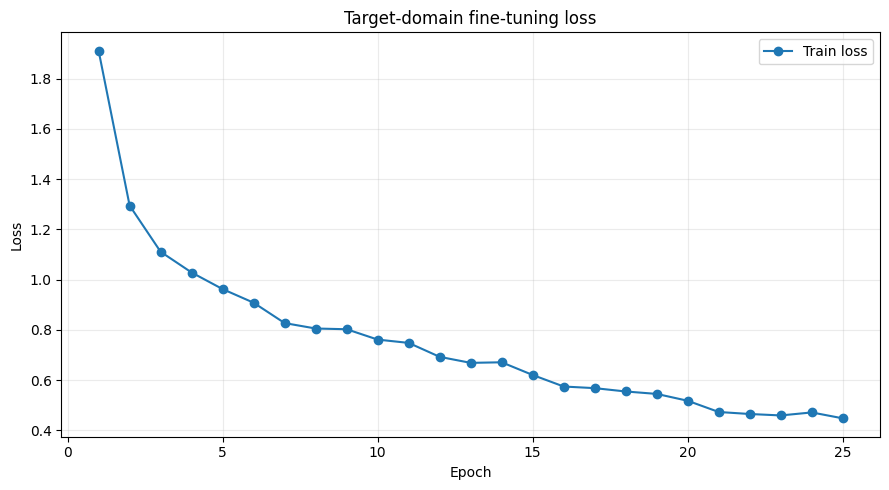

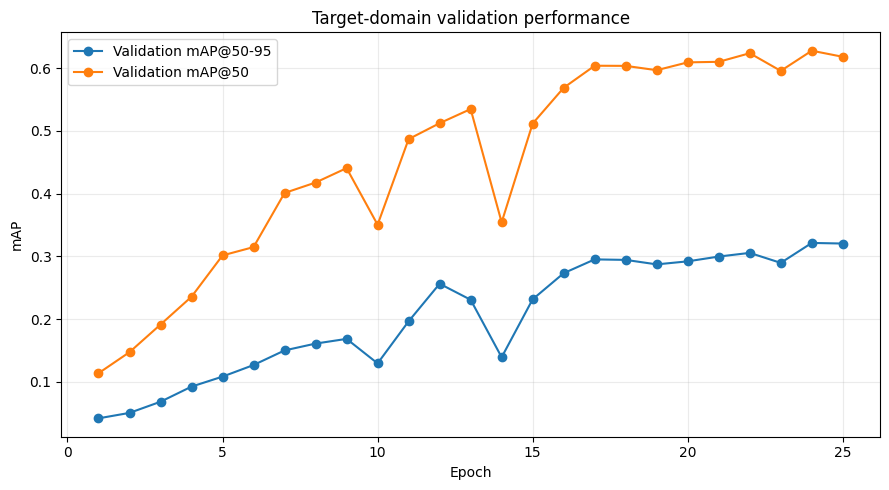

In [13]:
history_df = pd.read_csv(
    METRICS_DIR / "finetune_history.csv"
)

plt.figure(figsize=(9, 5))
plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    marker="o",
    label="Train loss",
)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Target-domain fine-tuning loss")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.savefig(
    PLOTS_DIR / "finetune_loss.png",
    dpi=180,
)
plt.show()

plt.figure(figsize=(9, 5))
plt.plot(
    history_df["epoch"],
    history_df["val_mAP50_95"],
    marker="o",
    label="Validation mAP@50-95",
)
plt.plot(
    history_df["epoch"],
    history_df["val_mAP50"],
    marker="o",
    label="Validation mAP@50",
)
plt.xlabel("Epoch")
plt.ylabel("mAP")
plt.title("Target-domain validation performance")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.savefig(
    PLOTS_DIR / "validation_map.png",
    dpi=180,
)
plt.show()

## 14. Reload the best validation checkpoint before touching the 70% test split

In [14]:
best_ckpt = torch.load(
    BEST_FINETUNED_PT,
    map_location="cpu",
    weights_only=False,
)

model.load_state_dict(
    best_ckpt["model_state"],
    strict=True,
)

model = model.to(DEVICE)
model.eval()

for p in model.parameters():
    p.requires_grad = False

print("Loaded best fine-tuned epoch:", best_ckpt["epoch"])
print("Best validation mAP50-95:", best_ckpt["best_val_map50_95"])
print("Trainable parameters now:", sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
))
print("✅ Final test evaluation can now begin.")

Loaded best fine-tuned epoch: 24
Best validation mAP50-95: 0.3213942050933838
Trainable parameters now: 0
✅ Final test evaluation can now begin.


## 15. Test-set matching helpers

In [15]:
def greedy_counts(
    pred,
    target,
    conf=CONF_THRESHOLD,
    iou_thr=MATCH_IOU_THRESHOLD,
):
    pboxes = pred["boxes"][
        pred["scores"] >= conf
    ]
    pscores = pred["scores"][
        pred["scores"] >= conf
    ]
    gboxes = target["boxes"].cpu()

    if len(pboxes) == 0:
        return 0, 0, len(gboxes), []

    order = torch.argsort(
        pscores,
        descending=True
    )
    pboxes = pboxes[order]

    if len(gboxes) == 0:
        return 0, len(pboxes), 0, []

    ious = box_iou(
        pboxes,
        gboxes
    )

    used = set()
    tp = 0
    matched = []

    for i in range(len(pboxes)):
        vals, idx = torch.sort(
            ious[i],
            descending=True
        )

        for value, j in zip(
            vals.tolist(),
            idx.tolist()
        ):
            if (
                j not in used
                and value >= iou_thr
            ):
                used.add(j)
                tp += 1
                matched.append(value)
                break

    fp = len(pboxes) - tp
    fn = len(gboxes) - tp
    return tp, fp, fn, matched

## 16. Final evaluation on the same untouched 70% test split

This is the directly comparable counterpart to Notebook 13.

In [16]:
metric = MeanAveragePrecision(
    box_format="xyxy",
    iou_type="bbox",
    class_metrics=False,
)

TP = FP = FN = 0
matched_ious = []
records = []
all_visual = []

# Warm-up.
with torch.inference_mode():
    sample_img, _, _ = test_dataset[0]
    for _ in range(3):
        _ = model([
            sample_img.to(DEVICE)
        ])

torch.cuda.synchronize()
start = time.perf_counter()
total_images = 0

with torch.inference_mode():
    for batch_idx, (images, targets, paths) in enumerate(test_loader):
        gpu_images = [
            image.to(
                DEVICE,
                non_blocking=True
            )
            for image in images
        ]

        outputs = model(gpu_images)

        preds = []
        metric_targets = []

        for output, target, path in zip(
            outputs,
            targets,
            paths,
        ):
            pred = metric_ready_prediction(
                output,
                conf_for_map=0.001
            )

            gt = {
                "boxes": target["boxes"].cpu(),
                "labels": torch.zeros(
                    (len(target["boxes"]),),
                    dtype=torch.int64,
                ),
            }

            preds.append(pred)
            metric_targets.append(gt)

            tp, fp, fn, mios = greedy_counts(
                pred,
                gt
            )

            TP += tp
            FP += fp
            FN += fn
            matched_ious.extend(mios)

            records.append({
                "image": Path(path).name,
                "gt_boxes": len(gt["boxes"]),
                "pred_boxes_map": len(pred["boxes"]),
                "pred_boxes_conf025": int(
                    (
                        pred["scores"]
                        >= CONF_THRESHOLD
                    ).sum()
                ),
                "tp": tp,
                "fp": fp,
                "fn": fn,
            })

            if len(all_visual) < 12:
                all_visual.append(
                    (path, pred, gt)
                )

        metric.update(
            preds,
            metric_targets
        )

        total_images += len(images)

        if (batch_idx + 1) % 20 == 0:
            print(
                f"Processed "
                f"{total_images}/{len(test_dataset)}"
            )

torch.cuda.synchronize()
elapsed = time.perf_counter() - start

map_result = metric.compute()

precision = (
    TP / (TP + FP)
    if TP + FP
    else 0.0
)
recall = (
    TP / (TP + FN)
    if TP + FN
    else 0.0
)
f1 = (
    2 * precision * recall
    / (precision + recall)
    if precision + recall
    else 0.0
)

mean_iou = (
    float(np.mean(matched_ious))
    if matched_ious
    else float("nan")
)

results = {
    "model": "PVT-MAAG + TA-DGNN",
    "protocol": "cross-dataset target fine-tuning; class-agnostic defect localization",
    "external_dataset": "PV-Multi-Defect processed",
    "split_protocol": "20% finetune / 10% validation / 70% untouched test",
    "fine_tuning": True,
    "finetune_images_used": len(train_dataset),
    "validation_images_used": len(val_dataset),
    "test_images_used": len(test_dataset),
    "best_epoch": int(best_epoch),
    "best_val_map50_95": float(best_val_map),
    "precision_at_0.25": precision,
    "recall_at_0.25": recall,
    "f1_at_0.25": f1,
    "map50": float(map_result["map_50"]),
    "map75": float(map_result["map_75"]),
    "map50_95": float(map_result["map"]),
    "matched_mean_iou_at_0.25_iou0.50": mean_iou,
    "tp": TP,
    "fp": FP,
    "fn": FN,
    "elapsed_seconds": elapsed,
    "ms_per_image": 1000 * elapsed / len(test_dataset),
    "fps": len(test_dataset) / elapsed,
    "confidence_for_prf1": CONF_THRESHOLD,
    "match_iou": MATCH_IOU_THRESHOLD,
    "collapsed_nms_iou": COLLAPSED_NMS_IOU,
}

pd.DataFrame([results]).to_csv(
    METRICS_DIR / "cross_dataset_finetuned_metrics.csv",
    index=False
)

pd.DataFrame(records).to_csv(
    METRICS_DIR / "per_image_test_results.csv",
    index=False
)

with open(
    METRICS_DIR / "cross_dataset_finetuned_metrics.json",
    "w"
) as f:
    json.dump(
        results,
        f,
        indent=2
    )

display(
    pd.DataFrame([results])
    .T
    .rename(columns={0: "value"})
)

Processed 80/774
Processed 160/774
Processed 240/774
Processed 320/774
Processed 400/774
Processed 480/774
Processed 560/774
Processed 640/774
Processed 720/774


,value
model,PVT-MAAG + TA-DGNN
protocol,cross-dataset target fine-tuning; class-agnost...
external_dataset,PV-Multi-Defect processed
split_protocol,20% finetune / 10% validation / 70% untouched ...
fine_tuning,True
finetune_images_used,221
validation_images_used,110
test_images_used,774
best_epoch,24
best_val_map50_95,0.321394


## 17. Compare against Notebook 13 zero-shot result

In [17]:
zero_shot_candidates = [
    CSE_ROOT
    / "13_CrossDataset_NoFineTune_TADGNN_70Test"
    / "metrics"
    / "cross_dataset_zero_shot_metrics.csv",
    CSE_ROOT
    / "13_CrossDataset_NoFineTune_TADGNN_70Test"
    / "metrics"
    / "paper_ready_cross_dataset_table.csv",
]

zero_shot_map = None
zero_shot_precision = None
zero_shot_recall = None
zero_shot_f1 = None
zero_shot_source = None

for path in zero_shot_candidates:
    if not path.exists():
        continue

    try:
        df = pd.read_csv(path)
        row = df.iloc[-1]

        for candidate in [
            "map50_95",
            "mAP@50-95",
        ]:
            if candidate in df.columns:
                zero_shot_map = float(row[candidate])
                break

        for candidate in [
            "precision_at_0.25",
            "Precision",
        ]:
            if candidate in df.columns:
                zero_shot_precision = float(row[candidate])
                break

        for candidate in [
            "recall_at_0.25",
            "Recall",
        ]:
            if candidate in df.columns:
                zero_shot_recall = float(row[candidate])
                break

        for candidate in [
            "f1_at_0.25",
            "F1",
        ]:
            if candidate in df.columns:
                zero_shot_f1 = float(row[candidate])
                break

        if zero_shot_map is not None:
            zero_shot_source = str(path)
            break
    except Exception:
        pass

comparison_rows = []

if zero_shot_map is not None:
    comparison_rows.append({
        "Model": "PVT-MAAG + TA-DGNN",
        "Target fine-tuning": "No",
        "Fine-tune images": 0,
        "Validation images": 0,
        "Test images": len(test_dataset),
        "Precision": zero_shot_precision,
        "Recall": zero_shot_recall,
        "F1": zero_shot_f1,
        "mAP@50-95": zero_shot_map,
    })

comparison_rows.append({
    "Model": "PVT-MAAG + TA-DGNN",
    "Target fine-tuning": "Yes",
    "Fine-tune images": len(train_dataset),
    "Validation images": len(val_dataset),
    "Test images": len(test_dataset),
    "Precision": results["precision_at_0.25"],
    "Recall": results["recall_at_0.25"],
    "F1": results["f1_at_0.25"],
    "mAP@50-95": results["map50_95"],
})

comparison = pd.DataFrame(comparison_rows)

if zero_shot_map is not None:
    gain = results["map50_95"] - zero_shot_map
    relative_gain = (
        100 * gain / zero_shot_map
        if zero_shot_map > 0
        else float("nan")
    )
    print("Zero-shot source:", zero_shot_source)
    print("Absolute mAP@50-95 gain:", gain)
    print("Relative mAP@50-95 gain (%):", relative_gain)
else:
    gain = float("nan")
    print(
        "Notebook 13 zero-shot CSV was not found automatically. "
        "Fine-tuned result is still valid."
    )

display(comparison)

comparison.to_csv(
    METRICS_DIR / "zero_shot_vs_finetuned.csv",
    index=False
)

Zero-shot source: /content/drive/MyDrive/Study Materials /CSE465/13_CrossDataset_NoFineTune_TADGNN_70Test/metrics/cross_dataset_zero_shot_metrics.csv
Absolute mAP@50-95 gain: 0.3319807513616979
Relative mAP@50-95 gain (%): 6248.399803570527


,Model,Target fine-tuning,Fine-tune images,Validation images,Test images,Precision,Recall,F1,mAP@50-95
0,PVT-MAAG + TA-DGNN,No,0,0,774,0.021080,0.017647,0.019212,0.005313
1,PVT-MAAG + TA-DGNN,Yes,221,110,774,0.480591,0.764706,0.590238,0.337294


## 18. Save qualitative test predictions

In [18]:
def draw_example(path, pred, target, out_path):
    image = Image.open(path).convert("RGB")
    draw = ImageDraw.Draw(image)

    for box in target["boxes"]:
        x1, y1, x2, y2 = box.tolist()
        draw.rectangle(
            [x1, y1, x2, y2],
            outline="white",
            width=3,
        )
        draw.text(
            (x1, max(0, y1 - 13)),
            "GT defect",
            fill="white",
        )

    keep = pred["scores"] >= CONF_THRESHOLD

    for box, score in zip(
        pred["boxes"][keep],
        pred["scores"][keep],
    ):
        x1, y1, x2, y2 = box.tolist()
        draw.rectangle(
            [x1, y1, x2, y2],
            outline="gray",
            width=3,
        )
        draw.text(
            (x1, y1),
            f"Pred {float(score):.2f}",
            fill="gray",
        )

    image.save(out_path)

for i, (path, pred, target) in enumerate(all_visual):
    draw_example(
        path,
        pred,
        target,
        PRED_DIR / f"{i:02d}_{Path(path).name}",
    )

print("Saved examples to:", PRED_DIR)

Saved examples to: /content/drive/MyDrive/Study Materials /CSE465/14_CrossDataset_FineTune_TADGNN/predictions


## 19. Paper-ready fine-tuning result

In [19]:
paper_table = pd.DataFrame([{
    "Model": "PVT-MAAG + TA-DGNN",
    "Source Training": "Modified PVEL-AD",
    "Target Dataset": "PV-Multi-Defect",
    "Fine-tuning": "20% target split",
    "Validation": "10% target split",
    "External Test": "Fixed untouched 70% target split",
    "Evaluation": "Class-agnostic defect localization",
    "Best Epoch": results["best_epoch"],
    "Precision": round(
        results["precision_at_0.25"],
        4
    ),
    "Recall": round(
        results["recall_at_0.25"],
        4
    ),
    "F1": round(
        results["f1_at_0.25"],
        4
    ),
    "mAP@50": round(
        results["map50"],
        4
    ),
    "mAP@50-95": round(
        results["map50_95"],
        4
    ),
    "Zero-shot-to-finetuned mAP@50-95 gain": (
        round(gain, 4)
        if np.isfinite(gain)
        else np.nan
    ),
}])

display(paper_table)

paper_table.to_csv(
    METRICS_DIR / "paper_ready_finetuned_table.csv",
    index=False
)

print(
    "✅ Notebook 14 complete — fine-tuned on 20%, "
    "selected on 10% validation, evaluated on the same untouched 70% test split."
)

,Model,Source Training,Target Dataset,Fine-tuning,Validation,External Test,Evaluation,Best Epoch,Precision,Recall,F1,mAP@50,mAP@50-95,Zero-shot-to-finetuned mAP@50-95 gain
0,PVT-MAAG + TA-DGNN,Modified PVEL-AD,PV-Multi-Defect,20% target split,10% target split,Fixed untouched 70% target split,Class-agnostic defect localization,24,0.4806,0.7647,0.5902,0.6722,0.3373,0.332


✅ Notebook 14 complete — fine-tuned on 20%, selected on 10% validation, evaluated on the same untouched 70% test split.
